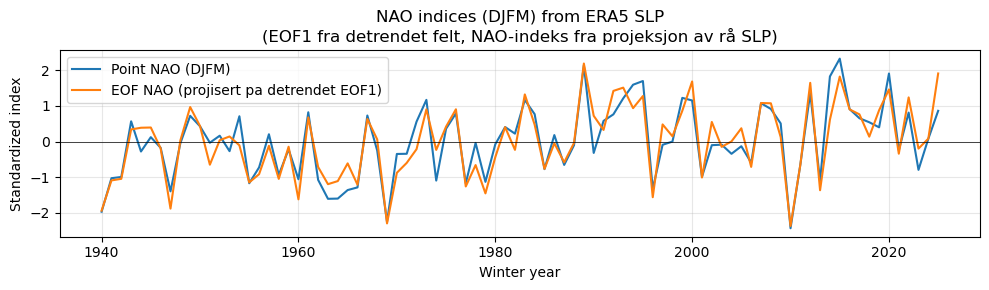

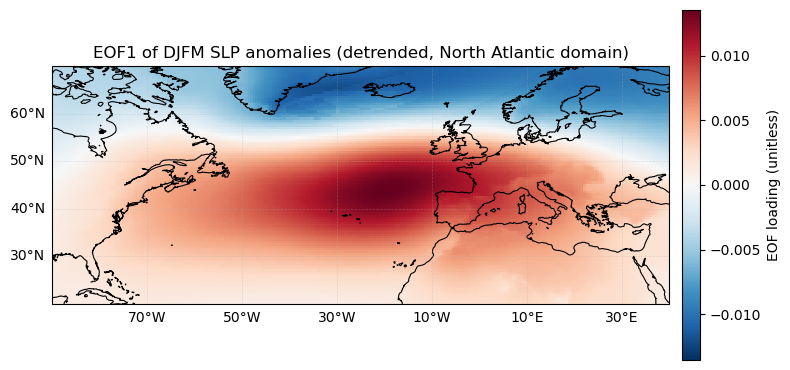

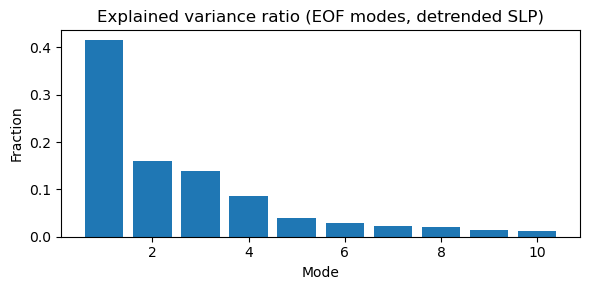

In [1]:
# NAO index (DJFM) fra ERA5 SLP (månedlig):
# 1) Punkt-basert (Azores-Iceland) indeks
# 2) EOF-basert NAO (PC1) over North Atlantic uved å bruke xeofs

# Input fil: slp_era5_1940-2024.nc  (variable: msl i Pa)

# METODE (oppdatert etter tilbakemelding fra Ole):
# EOF-modellen fittes på det DETRENDEDE SLP-feltet, for å sikre at EOF1
# fanger intern variabilitet og ikke domineres av en langtidstrend.
# NAO-indeksen (nao_eof_raw) beregnes deretter ved å projisere det ikke-detrendede
# (rå) SLP-feltet på dette EOF1-monsteret (model.transform).
# Dette gir en NAO-indeks som inneholder bade forced og intern variabilitet,
# slik at forced signal removal med MMEM i neste steg faktisk har noe a fjerne.
# Hvis man i stedet hadde brukt PC1 fra den detrendede EOF-fitten direkte,
# ville NAO-indeksen allerede vaert "intern" (relativt til en lineaer trend),
# og MMEM ville hatt lite igjen a fjerne.


import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import matplotlib.ticker as mticker
import xeofs as xe

# Input 
SLP_FILE = "/projects/NS9873K/www/scenarios_2050/wind_power_production_dataset/monthly_aggregation/slp_era5_1940-2024.nc"
SLP_VAR  = "msl"

# Koordinater for punktbasert NAO
AZORES_LAT,  AZORES_LON  = 38.5, -28.0
ICELAND_LAT, ICELAND_LON = 65.0, -17.5

# North Atlantic domain (for EOF analysen)
LAT_MIN, LAT_MAX = 20.0, 70.0
LON_MIN, LON_MAX = -90.0, 40.0

N_MODES = 10


# Hjelpefunksjoner
    # ERA5 gir longitude i 0-360 konvensjon.
    # Konverterer til -180-180 slik at Nord-Atlanteren kan defineres som ett sammenhengende intervall.
def to_lon180(da, lon_name="longitude"):
    lon = da[lon_name]
    if float(lon.max()) > 180:
        da = da.assign_coords(**{lon_name: (((lon + 180) % 360) - 180)})
        da = da.sortby(lon_name)
    return da

def add_season_year_dec(da):
    # Tilordner desember til påfølgende kalenderår, slik at
    # DJFM-sesongen representerer en sammenhengende vinter.
    # (F.eks. blir desember 2020 + jan-mar 2021 til "vinter 2021".)
    t = da["time"]
    sy = xr.where(t.dt.month == 12, t.dt.year + 1, t.dt.year)
    return da.assign_coords(season_year=sy)

def seasonal_mean_djfm(da):
    # Beregner DJFM sesongmiddel med desember tilordnet påfølgende år.
    da = da.sel(time=da["time.month"].isin([12, 1, 2, 3]))
    da = add_season_year_dec(da)
    return da.groupby("season_year").mean("time").rename({"season_year": "time"})

def standardize_1d(x, dim="time"):
    # Standardiserer en tidsserie (trekker fra middel, deler på std).
    # Brukes kun for plotting og sammenligning
    return (x - x.mean(dim)) / x.std(dim)

def select_lat_slice(da, lat_name, lat_min, lat_max):
    lat0 = float(da[lat_name][0])
    latN = float(da[lat_name][-1])
    if lat0 > latN:
        return da.sel({lat_name: slice(lat_max, lat_min)})
    else:
        return da.sel({lat_name: slice(lat_min, lat_max)})


def detrend_gridpoint(da, dim="time"):
    # Lineaer detrending gridpoint-for-gridpoint langs tidsdimensjonen
    times = da[dim]
    t_vals = xr.DataArray(
        np.arange(len(times), dtype=float),
        coords={dim: times},
        dims=[dim]
    )
    p = da.polyfit(dim=dim, deg=1)
    trend = xr.polyval(coord=t_vals, coeffs=p.polyfit_coefficients)
    return da - trend



# 1) Laster inn SLP
ds = xr.open_dataset(SLP_FILE)
slp = ds[SLP_VAR] / 100.0  # Pa -> hPa
slp.attrs["units"] = "hPa"

lat_name = "latitude" if "latitude" in slp.coords else "lat"
lon_name = "longitude" if "longitude" in slp.coords else "lon"

slp = to_lon180(slp, lon_name=lon_name)


# 2) DJFM sesongmiddel (rådata, ikke detrendet ennå)
slp_djfm = seasonal_mean_djfm(slp)

# 3) Lineaer detrending gridpoint-for-gridpoint
#    Brukes KUN til a fitte EOF-modellen (for et stabilt EOF1-monster
#    uten trend-forurensning). Det undetrendede feltet beholdes separat
#    og brukes til selve NAO-projeksjonen (steg 5b).

slp_djfm_detrended = detrend_gridpoint(slp_djfm, dim="time")
slp_djfm_detrended_anom = slp_djfm_detrended - slp_djfm_detrended.mean("time")

# Anomalier av det UNDETRENDEDE feltet (kun fjern tidsmiddel)
slp_djfm_raw_anom = slp_djfm - slp_djfm.mean("time")


# 4) Punkt-basert NAO (DJFM) - fra rådata, ikke detrendet
az = slp_djfm.sel({lat_name: AZORES_LAT, lon_name: AZORES_LON}, method="nearest")
ic = slp_djfm.sel({lat_name: ICELAND_LAT, lon_name: ICELAND_LON}, method="nearest")

dp = az - ic
nao_point_djfm = standardize_1d(dp)
nao_point_djfm.name = "NAO_point_DJFM"


# 5a) Fit EOF-modell PA DET DETRENDEDE feltet
slp_na_detrended = select_lat_slice(slp_djfm_detrended_anom, lat_name, LAT_MIN, LAT_MAX).sel(
    {lon_name: slice(LON_MIN, LON_MAX)}
)

model = xe.single.EOF(n_modes=N_MODES, use_coslat=True)
model.fit(slp_na_detrended, dim="time")

eofs    = model.components()
varfrac = model.explained_variance_ratio()
varfrac.name = "explained_variance_ratio"


# 5b) PROJISER DET UNDETRENDEDE (rå) feltet pa EOF1-monsteret
#     -> gir en NAO-indeks som inneholder bade forced og intern
#        variabilitet (Ole sin anbefaling)
slp_na_raw = select_lat_slice(slp_djfm_raw_anom, lat_name, LAT_MIN, LAT_MAX).sel(
    {lon_name: slice(LON_MIN, LON_MAX)}
)

pcs_projected = model.transform(slp_na_raw)  # PC-skarer fra projeksjon av rå data

pc1 = pcs_projected.isel(mode=0)

# Standardisert versjon (til plotting)
nao_eof_djfm = standardize_1d(pc1)
nao_eof_djfm.name = "NAO_eof_PC1_DJFM"

# Ustandardisert versjon (til forced signal removal)
nao_eof_raw = pc1.copy()
nao_eof_raw.name = "NAO_eof_raw"


# 6) Fortegnsjustering mot punkt-indeks
nao_eof_al, nao_point_al = xr.align(nao_eof_djfm, nao_point_djfm, join="inner")
corr = xr.corr(nao_eof_al, nao_point_al, dim="time")

if float(corr) < 0:
    nao_eof_djfm     = -nao_eof_djfm
    nao_eof_raw       = -nao_eof_raw
    pcs_projected     = -pcs_projected
    eofs              = -eofs

pcs = pcs_projected  



# 7) Plott: tidsserier
plt.figure(figsize=(10, 3))
plt.plot(nao_point_djfm["time"], nao_point_djfm, label="Point NAO (DJFM)", linewidth=1.5)
plt.plot(nao_eof_djfm["time"],   nao_eof_djfm,   label="EOF NAO (projisert pa detrendet EOF1)", linewidth=1.5)
plt.axhline(0, color="k", linewidth=0.5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("NAO indices (DJFM) from ERA5 SLP\n(EOF1 fra detrendet felt, NAO-indeks fra projeksjon av rå SLP)")
plt.xlabel("Winter year")
plt.ylabel("Standardized index")
plt.tight_layout()
plt.show()

# 8) Plott: EOF1 (romlig monster)
eof1 = eofs.isel(mode=0)

lat_name_e = "latitude" if "latitude" in eof1.coords else "lat"
lon_name_e  = "longitude" if "longitude" in eof1.coords else "lon"

lats = eof1[lat_name_e].values
lons = eof1[lon_name_e].values
Z    = eof1.values

Z_cyc, lons_cyc = add_cyclic_point(Z, coord=lons)
Lon, Lat = np.meshgrid(lons_cyc, lats)
vmax = np.nanmax(np.abs(Z_cyc))

fig = plt.figure(figsize=(8, 3.8))
ax  = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=ccrs.PlateCarree())

im = ax.pcolormesh(
    Lon, Lat, Z_cyc,
    transform=ccrs.PlateCarree(),
    shading="auto",
    cmap="RdBu_r",
    vmin=-vmax, vmax=vmax
)

ax.coastlines(linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.25, zorder=0)

cb = plt.colorbar(im, ax=ax, orientation="vertical", pad=0.02, fraction=0.05)
cb.set_label("EOF loading (unitless)")

ax.set_title("EOF1 of DJFM SLP anomalies (detrended, North Atlantic domain)")

gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.3, linestyle="--")
gl.top_labels   = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-90, 50, 20))
gl.ylocator = mticker.FixedLocator(np.arange(20, 80, 10))

plt.tight_layout()
plt.show()

# 9) Plott: forklart varians
plt.figure(figsize=(6, 3))
plt.bar(varfrac["mode"].values, varfrac.values)
plt.title("Explained variance ratio (EOF modes, detrended SLP)")
plt.xlabel("Mode")
plt.ylabel("Fraction")
plt.tight_layout()
plt.show()

In [2]:
# Aggregering av energidata til sesong/år
# Energidata er månedlige summer (kWh). Denne koden aggregerer til valgt periode (ANNUAL, DJFM eller JJA) ved å summere månedsverdiene. 


def aggregate_annual_strict(da):
    # Summerer alle 12 måneder per kalenderår.
    # År med færre enn 12 måneder forkastes.
    g = da.groupby("time.year")
    out = g.sum("time")
    n = g.count("time")
    out = out.where(n == 12, drop=True)
    out = out.rename({"year": "time"})
    out = out.assign_coords(time=out["time"].astype(int))
    return out

def aggregate_jja_strict(da):
    # Summerer juni, juli og august per år.
    # År med færre enn 3 måneder forkastes.
    da_jja = da.where(da["time"].dt.month.isin([6, 7, 8]), drop=True)
    g = da_jja.groupby("time.year")
    out = g.sum("time")
    n = g.count("time")
    out = out.where(n == 3, drop=True)
    out = out.rename({"year": "time"})
    out = out.assign_coords(time=out["time"].astype(int))
    return out

def aggregate_djfm_strict(da):
    # Summerer desember, januar, februar og mars per vintersesong.
    # Desember tilordnes påfølgende år (konsistent med NAO-koden).
    # Sesonger med færre enn 4 måneder forkastes.
    da_djfm = da.where(da["time"].dt.month.isin([12, 1, 2, 3]), drop=True)
    months = da_djfm["time"].dt.month
    season_year = xr.where(months == 12, da_djfm["time"].dt.year + 1, da_djfm["time"].dt.year)
    da_djfm = da_djfm.assign_coords(season_year=("time", season_year.data))
    g = da_djfm.groupby("season_year")
    out = g.sum("time")
    n = g.count("time")
    out = out.where(n == 4, drop=True)
    out = out.rename({"season_year": "time"})
    out = out.assign_coords(time=out["time"].astype(int))
    return out

def aggregate_energy(da, period):
    # Velger aggregeringsfunksjon basert på valgt periode.
    period = period.upper()
    if period == "ANNUAL":
        return aggregate_annual_strict(da)
    elif period == "JJA":
        return aggregate_jja_strict(da)
    elif period == "DJFM":
        return aggregate_djfm_strict(da)
    else:
        raise ValueError("period must be 'ANNUAL', 'JJA', or 'DJFM'")

In [3]:
#Veld område og sensong


import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


# filene
ENERGY_FILE = "/projects/NS9873K/www/scenarios_2050/wind_power_production_dataset/monthly_aggregation/N175-120m_dry-dens_1940-2024.nc"
ENERGY_VAR  = "energy"
LSM_FILE    = "/projects/NS9873K/www/scenarios_2050/wind_power_production_dataset/monthly_aggregation/land_sea_mask.nc"
LSM_VAR     = "lsm"
MMEM_FILE   = "/projects/NS9873K/www/scenarios_2050/wind_power_production_dataset/NAO_MMEM.nc"
MMEM_VAR    = "scores"

# Velg region
REGION_NAME = "Scandinavia"
REG_BOX_LAT = (54.5, 70.0)
REG_BOX_LON = (4.5, 18.5)
#REGION_NAME = "Iberia"
#REG_BOX_LAT = (36.5, 43.8)
#REG_BOX_LON = (-9.5, 3.5)
# REGION_NAME = "UK"
# REG_BOX_LAT = (49.5, 59.0)
# REG_BOX_LON = (-10.5, 2.5)
# REGION_NAME = "Germany"
# REG_BOX_LAT = (47.5, 55.0)
# REG_BOX_LON = (6.0, 15.0)

# Velg periode
PERIOD = "ANNUAL"   # "ANNUAL", "DJFM", eller "JJA"

WINDOW          = 9
YEAR_MIN        = 1940
YEAR_MAX        = 2024
ENERGY_SCALE    = 1e6
ENERGY_LABEL    = r"Internal energy anomaly ($10^6$ kWh)"
MIN_TRAIN_WINDOWS = 3


# NAO-indeks (fra NAO-koden, første kode)
nao_index = nao_eof_raw   

In [4]:
# Hjelpefunksjoner 


def guess_latlon_names(da):
    lat = "latitude" if "latitude" in da.coords else ("lat" if "lat" in da.coords else None)
    lon = "longitude" if "longitude" in da.coords else ("lon" if "lon" in da.coords else None)
    if lat is None or lon is None:
        raise ValueError("Fant ikke lat/lon koordinatnavn.")
    return lat, lon

def to_lon180(da, lon_name="lon"):
    lon = da[lon_name]
    lon180 = ((lon + 180) % 360) - 180
    return da.assign_coords({lon_name: lon180}).sortby(lon_name)

def region_slices(da, lat_name, lon_name, lat_bounds, lon_bounds):
    lat0 = float(da[lat_name].values[0])
    lat1 = float(da[lat_name].values[-1])
    lat_min, lat_max = min(lat_bounds), max(lat_bounds)
    lat_sl = slice(lat_min, lat_max) if lat0 < lat1 else slice(lat_max, lat_min)
    lon_sl = slice(min(lon_bounds), max(lon_bounds))
    return lat_sl, lon_sl

def make_coslat_2d(lat_coord, lon_coord, lat_name, lon_name):
    coslat_1d = xr.DataArray(
        np.cos(np.deg2rad(lat_coord.values)),
        coords={lat_name: lat_coord}, dims=(lat_name,)
    )
    ones_lon = xr.DataArray(
        np.ones(len(lon_coord)),
        coords={lon_name: lon_coord}, dims=(lon_name,)
    )
    return coslat_1d * ones_lon

def area_weighted_land_mean(field, lsm2d, domain_mask2d, lat_name, lon_name):
    # Beregner arealveid middelverdi over landpunkter i regionen.
    # Vektene er produktet av cos(lat) og land/hav-masken,
    # slik at havpunkter og høyere breddegrader vektes riktig.
    coslat2d  = make_coslat_2d(field[lat_name], field[lon_name], lat_name, lon_name)
    weights2d = coslat2d * lsm2d * domain_mask2d
    weights3d = weights2d.broadcast_like(field)
    valid     = (~field.isnull()) & (~weights3d.isnull())
    num = (field.where(valid) * weights3d.where(valid)).sum(dim=[lat_name, lon_name])
    den = weights3d.where(valid).sum(dim=[lat_name, lon_name])
    return xr.where(den > 0, num / den, np.nan)

def center_over_period(da, y1, yY, dim):
    # Sentrerer tidsserie over felles analyseperiode (trekker fra middel).
    # Gjøres konsistent for alle datasett over samme periode (YEAR_MIN-YEAR_MAX)
    return da - da.sel({dim: slice(y1, yY)}).mean(dim)

def remove_forced_signal(X, mmem, x_dim="time", m_dim="year"):
    # Fjerner forced signal fra X ved lineær regresjon på MMEM.
    # gamma = Cov(X, MMEM) / Var(MMEM)
    # X_int = X - gamma * MMEM
    # Samme gamma-formel brukes på både NAO og energi for konsistens.
    
    mmem_r = mmem.rename({m_dim: x_dim})
    X_al, mmem_al = xr.align(X, mmem_r, join="inner")
    gamma    = xr.cov(X_al, mmem_al, dim=x_dim) / mmem_al.var(x_dim)
    X_forced = gamma * mmem_al
    X_int    = X_al - X_forced
    return X_int, X_forced, float(gamma)

def running_mean(da, window=9, dim="time"):
    # 9-års sentrert glidende gjennomsnitt.
    # Brukes på interne komponenter etter forced signal removal,
    return da.rolling({dim: window}, center=True, min_periods=window).mean()

In [5]:
# Fjerne forced signal

# Laster inn data
dsE    = xr.open_dataset(ENERGY_FILE)
energy = dsE[ENERGY_VAR]
latE, lonE = guess_latlon_names(energy)
energy = to_lon180(energy, lon_name=lonE)

dsM  = xr.open_dataset(LSM_FILE)
lsm  = dsM[LSM_VAR]
latM, lonM = guess_latlon_names(lsm)
lsm  = to_lon180(lsm, lon_name=lonM)
lsm  = lsm.sel({latM: energy[latE], lonM: energy[lonE]})
# lsm  = lsm.rename({latM: latE, lonM: lonE})

# Aggreger til valgt periode
energy_agg = aggregate_energy(energy, PERIOD)
print(f"Energidata ({PERIOD}): {int(energy_agg.time[0])}–{int(energy_agg.time[-1])}")

# Arealveid regionmiddel
lat_sl, lon_sl = region_slices(energy_agg, latE, lonE, REG_BOX_LAT, REG_BOX_LON)
energy_box  = energy_agg.sel({latE: lat_sl, lonE: lon_sl})
lsm_box     = lsm.sel({latE: lat_sl, lonE: lon_sl})
domain_box  = xr.ones_like(lsm_box)

y_box = area_weighted_land_mean(
    field=energy_box, lsm2d=lsm_box,
    domain_mask2d=domain_box,
    lat_name=latE, lon_name=lonE
).rename(f"Energy_{PERIOD}_{REGION_NAME}")


# Laster inn MMEM og fjerner forced signal
ds_mmem = xr.open_dataset(MMEM_FILE)
mmem    = ds_mmem[MMEM_VAR]
mmem = mmem.assign_coords(year=mmem.year+1)
print(f"MMEM periode: {int(mmem.year[0])}–{int(mmem.year[-1])}")

# Sentrer over felles analyseperiode (YEAR_MIN-YEAR_MAX, definert i kode 3)
# (tilbakemelding fra Lea og Ole: samme periode for alle datasett)

mmem_c   = center_over_period(mmem,      YEAR_MIN, YEAR_MAX, dim="year")
nao_c    = center_over_period(nao_index, YEAR_MIN, YEAR_MAX, dim="time")
energy_c = center_over_period(y_box,     YEAR_MIN, YEAR_MAX, dim="time")

# Fjern forced signal
nao_int,    nao_forced,    gamma_nao    = remove_forced_signal(nao_c,    mmem_c)
energy_int, energy_forced, gamma_energy = remove_forced_signal(energy_c, mmem_c)

print(f"\nGamma NAO:    {gamma_nao:.4f}")
print(f"Gamma energi: {gamma_energy:.4f}")

# 9-års running mean på interne komponenter
nao_int_smooth    = running_mean(nao_int).sel(time=slice(YEAR_MIN, YEAR_MAX))
energy_int_smooth = running_mean(energy_int).sel(time=slice(YEAR_MIN, YEAR_MAX))

# Fjern NaN
finite = (~nao_int_smooth.isnull()) & (~energy_int_smooth.isnull())
nao_int_smooth    = nao_int_smooth.where(finite, drop=True)
energy_int_smooth = energy_int_smooth.where(finite, drop=True)

print(f"\nAnalyseperiode etter smoothing: "
      f"{int(nao_int_smooth.time[0])}–{int(nao_int_smooth.time[-1])}")
print(f"Antall år: {nao_int_smooth.sizes['time']}")

Energidata (ANNUAL): 1940–2024
MMEM periode: 1851–2099

Gamma NAO:    987.7527
Gamma energi: 5927227.2945

Analyseperiode etter smoothing: 1944–2020
Antall år: 77


In [6]:
# Sjekk hvor mye varians som fjernes (bør være ~5-6% ifølge Ole)
var_nao_original = float(nao_c.var("time"))
var_nao_int      = float(nao_int.var("time"))
var_energy_original = float(energy_c.var("time"))
var_energy_int      = float(energy_int.var("time"))

pct_nao    = (1 - var_nao_int / var_nao_original) * 100
pct_energy = (1 - var_energy_int / var_energy_original) * 100

print(f"\nVarians fjernet fra NAO:    {pct_nao:.2f}%")
print(f"Varians fjernet fra energi: {pct_energy:.2f}%")


Varians fjernet fra NAO:    5.44%
Varians fjernet fra energi: 6.95%


In [7]:
# All-data fit (lineær regresjon)
# Trener modellen på alle tilgjengelige data (ikke kryssvalidert).
# Brukes til plotting og sammenligning med CV-resultatet.
# alpha (a) = regresjonskoeffisient, beta (b) = konstantledd

nao_al, energy_al = xr.align(nao_int_smooth, energy_int_smooth, join="inner")

X = nao_al.values.reshape(-1, 1)
Y = energy_al.values

model_all = LinearRegression().fit(X, Y)
Yhat      = model_all.predict(X)

corr_all = float(np.corrcoef(Y, Yhat)[0, 1])
r2_all   = float(r2_score(Y, Yhat))
rmse_all = float(np.sqrt(mean_squared_error(Y, Yhat)))

print(f"\nAll-data fit ({REGION_NAME}, {PERIOD}):")
print(f"  a    = {float(model_all.coef_[0]):.4f}")
print(f"  b    = {float(model_all.intercept_):.4f}")
print(f"  r    = {corr_all:.3f}")
print(f"  R²   = {r2_all:.3f}")
print(f"  RMSE = {rmse_all / ENERGY_SCALE:.3f} × 10⁶ kWh")

# lagrer resultatene for senere plotting
res = {
    "years": nao_al["time"].values,
    "y":     Y,
    "yhat":  Yhat,
    "corr":  corr_all,
    "r2":    r2_all,
    "rmse":  rmse_all,
}


All-data fit (Scandinavia, ANNUAL):
  a    = 4646.3523
  b    = -20057.4392
  r    = 0.892
  R²   = 0.795
  RMSE = 0.253 × 10⁶ kWh



Kryssvalidert skill (Scandinavia, ANNUAL):
  r    = 0.839
  R²   = 0.699
  RMSE = 0.308 × 10⁶ kWh
  Periode: 1945–2020
All-data RMSE = 0.253 × 10⁶ kWh
CV RMSE       = 0.308 × 10⁶ kWh


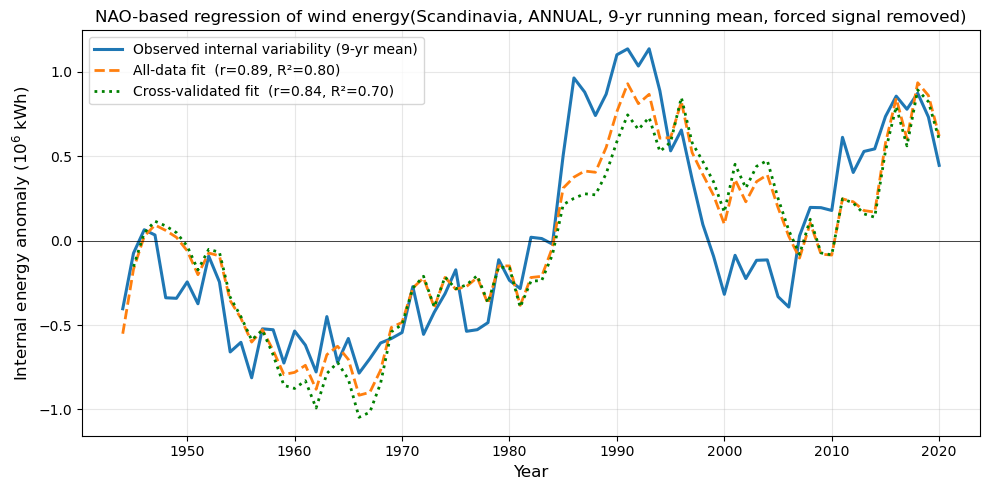

In [8]:
# Kryssvalidering 
# Blokkert leave-one-out CV med 9-års vinduer.
# Ingen forhånds 9y-glatting. Vindus-gjennomsnittet (9 års vinduer) er glattingen

def build_windows(x, y, start_year, end_year, window=9):
    # Bygger alle mulige 9-års vinduer over analyseperioden.
    # Hvert vindu representeres ved startår, sluttår og senterår.
    rows = []
    if end_year - start_year + 1 < window:
        return pd.DataFrame(rows)
    for start in range(start_year, end_year - window + 2):
        end = start + window - 1
        xw = x.sel(time=slice(start, end))
        yw = y.sel(time=slice(start, end))
        if xw.sizes["time"] == window and yw.sizes["time"] == window:
            rows.append({
                "start":       start,
                "end":         end,
                "center":      start + window // 2,
                "nao_mean":    float(xw.mean("time").values),
                "energy_mean": float(yw.mean("time").values),
            })
    return pd.DataFrame(rows)

def cv_internal(x, y, window=9, min_train=3, center_min=1945, center_max=2020):
    # Blokkert kryssvalidering: for hvert testvardu trenes modellen på alle vinduer som ikke overlapper med testvinduet.
    # alpha (a) og beta (b) estimeres per treningsvindu.
    x, y = xr.align(x, y, join="inner")
    raw_min = int(x["time"].min().values)
    raw_max = int(x["time"].max().values)

    all_windows = build_windows(x, y, raw_min, raw_max, window)
    if len(all_windows) == 0:
        raise ValueError("Ingen vinduer funnet.")

    results = []
    for i, test_row in all_windows.iterrows():
        test_start  = int(test_row["start"])
        test_end    = int(test_row["end"])
        test_center = int(test_row["center"])

        # Ekskluder alle overlappende vinduer fra treningen
        train_df = all_windows[
            (all_windows["end"]   < test_start) |
            (all_windows["start"] > test_end)
        ].copy()

        if len(train_df) < min_train:
            continue

        model_cv = LinearRegression().fit(
            train_df["nao_mean"].values.reshape(-1, 1),
            train_df["energy_mean"].values
        )
        results.append({
            "test_center": test_center,
            "energy_obs":  float(test_row["energy_mean"]),
            "energy_pred": float(model_cv.predict(
                np.array([[test_row["nao_mean"]]]))[0]),
            "a": float(model_cv.coef_[0]),
            "b": float(model_cv.intercept_),
        })

    res_cv = pd.DataFrame(results)
    res_cv = res_cv[
        (res_cv["test_center"] >= center_min) &
        (res_cv["test_center"] <= center_max)
    ].copy()

    if len(res_cv) == 0:
        raise ValueError("Ingen CV-resultater. Prøv å senke min_train.")

    rmse = np.sqrt(mean_squared_error(res_cv["energy_obs"], res_cv["energy_pred"]))
    corr = float(np.corrcoef(res_cv["energy_obs"], res_cv["energy_pred"])[0, 1])
    ss_res = np.sum((res_cv["energy_obs"] - res_cv["energy_pred"]) ** 2)
    ss_tot = np.sum((res_cv["energy_obs"] - np.mean(res_cv["energy_obs"])) ** 2)
    r2_cv  = 1 - ss_res / ss_tot

    return {"res_cv": res_cv, "rmse": rmse, "corr": corr, "r2_cv": r2_cv}

cv = cv_internal(
    x=nao_int,
    y=energy_int,
    window=WINDOW,
    min_train=MIN_TRAIN_WINDOWS,
)

print(f"\nKryssvalidert skill ({REGION_NAME}, {PERIOD}):")
print(f"  r    = {cv['corr']:.3f}")
print(f"  R²   = {cv['r2_cv']:.3f}")
print(f"  RMSE = {cv['rmse'] / ENERGY_SCALE:.3f} × 10⁶ kWh")
print(f"  Periode: {cv['res_cv']['test_center'].min()}–{cv['res_cv']['test_center'].max()}")


# ALL-DATA FIT (for plotting)
nao_al, energy_al = xr.align(nao_int_smooth, energy_int_smooth, join="inner")
X = nao_al.values.reshape(-1, 1)
Y = energy_al.values
model_all = LinearRegression().fit(X, Y)
Yhat      = model_all.predict(X)
corr_all  = float(np.corrcoef(Y, Yhat)[0, 1])
r2_all    = float(r2_score(Y, Yhat))
rmse_all  = float(np.sqrt(mean_squared_error(Y, Yhat)))

res = {
    "years": nao_al["time"].values,
    "y":     Y,
    "yhat":  Yhat,
    "corr":  corr_all,
    "r2":    r2_all,
    "rmse":  rmse_all,
}


# PLOTT: observed, all-data fit, cross-validated fit
res_cv = cv["res_cv"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    res["years"], res["y"] / ENERGY_SCALE,
    label="Observed internal variability (9-yr mean)",
    linewidth=2.2, color="tab:blue"
)
ax.plot(
    res["years"], res["yhat"] / ENERGY_SCALE,
    label=f"All-data fit  (r={res['corr']:.2f}, R²={res['r2']:.2f})",
    linewidth=2.0, color="tab:orange", linestyle="--"
)
ax.plot(
    res_cv["test_center"], res_cv["energy_pred"] / ENERGY_SCALE,
    label=f"Cross-validated fit  (r={cv['corr']:.2f}, R²={cv['r2_cv']:.2f})",
    linewidth=2.0, color="green", linestyle=":"
)
ax.axhline(0, color="k", linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(ENERGY_LABEL, fontsize=12)
ax.set_title(
    f"NAO-based regression of wind energy"
    f"({REGION_NAME}, {PERIOD}, {WINDOW}-yr running mean, forced signal removed)",
    fontsize=12
)
ax.legend(fontsize=10, frameon=True, facecolor="white", edgecolor="0.8")
print(f"All-data RMSE = {res['rmse'] / ENERGY_SCALE:.3f} × 10⁶ kWh")
print(f"CV RMSE       = {cv['rmse'] / ENERGY_SCALE:.3f} × 10⁶ kWh")
plt.tight_layout()
plt.show()

Metode D – Ensemble mean NAO, per-vindu CV-α (Scandinavia):
  r  = -0.406
  R² = -0.056

Metode B – Per-medlem, per-vindu CV-α (Scandinavia):
  Mean r/medlem  = -0.406  (std: 0.006)
  Mean R²/medlem = -0.019  (std: 0.039)


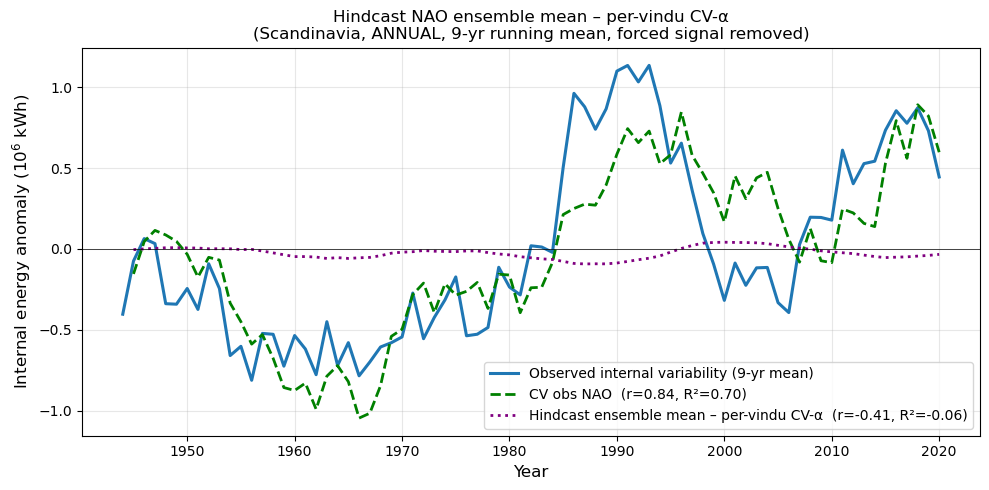

In [9]:
# Hindcast
# laster inn og strukturer data
# forced signal er fjernet av Ole fra før (i datasettet)
ds_hc  = xr.open_dataset("NAO_HadSLP_analog_hindcast_anomalies.nc")
scores = ds_hc["scores"]   # (init_year, member, lead_time)

# Bygg lang dataframe med kalenderår, medlem og score
hc_rows = []
for i, init_yr in enumerate(ds_hc["init_year"].values):
    for lt in ds_hc["lead_time"].values:
        cal_year = int(init_yr) + int(lt)
        for m in ds_hc["member"].values:
            score = float(scores.sel(init_year=init_yr, lead_time=lt, member=m).values)
            hc_rows.append({"cal_year": cal_year, "member": int(m), "score": score})

df_hc = pd.DataFrame(hc_rows)

#  Ensemble mean per kalenderår (midler over alle 100 medlemmer)
hc_rows_em = []
for i, init_yr in enumerate(ds_hc["init_year"].values):
    for lt in ds_hc["lead_time"].values:
        cal_year = int(init_yr) + int(lt)
        score_em = float(scores.sel(init_year=init_yr, lead_time=lt).mean(dim="member").values)
        hc_rows_em.append({"cal_year": cal_year, "score": score_em})

df_hc_em = pd.DataFrame(hc_rows_em)

# Ensemble mean per kalenderår (midler over alle 100 medlemmer)
cv_rows = cv["res_cv"].reset_index(drop=True)



# METODE 1: Ensemble mean NAO, per-vindu CV-α (Ole sin anbefalte tilnærming)
# Bruker ensemble-gjennomsnittet av hindcast-NAO som prediktor og per-vindu alpha/beta fra CV-modellen trent på reanalyse.
results_D = []
for _, row in cv_rows.iterrows():
    test_center = int(row["test_center"])
    test_start  = test_center - WINDOW // 2
    test_end    = test_center + WINDOW // 2

    # Henter hindcast-verdier for det aktuelle 9-års vinduet
    win = df_hc_em[
        (df_hc_em["cal_year"] >= test_start) &
        (df_hc_em["cal_year"] <= test_end)
    ]
    if len(win) < WINDOW:
        continue

    hc_nao      = float(win["score"].mean())
    alpha_w     = float(row["a"])
    beta_w      = float(row["b"])
    energy_pred = alpha_w * hc_nao + beta_w

    results_D.append({
        "test_center": test_center,
        "energy_obs":  float(row["energy_obs"]),
        "energy_pred": energy_pred,
    })

df_D = pd.DataFrame(results_D)
r_D  = float(np.corrcoef(df_D["energy_obs"], df_D["energy_pred"])[0, 1])
ss_res = np.sum((df_D["energy_obs"] - df_D["energy_pred"]) ** 2)
ss_tot = np.sum((df_D["energy_obs"] - np.mean(df_D["energy_obs"])) ** 2)
r2_D = 1 - ss_res / ss_tot

print(f"Metode D – Ensemble mean NAO, per-vindu CV-α ({REGION_NAME}):")
print(f"  r  = {r_D:.3f}")
print(f"  R² = {r2_D:.3f}")



# METODE 2: Per-ensemble-medlem, per-vindu CV-α (tilbakemelding: lineær modell gjør at rekkefølgen på snittet ikke spiller rolle)

member_records_B = []

for m in df_hc["member"].unique():
    df_m = df_hc[df_hc["member"] == m]
    m_results = []
    for _, row in cv_rows.iterrows():
        test_center = int(row["test_center"])
        test_start  = test_center - WINDOW // 2
        test_end    = test_center + WINDOW // 2

        win = df_m[
            (df_m["cal_year"] >= test_start) &
            (df_m["cal_year"] <= test_end)
        ]
        if len(win) < WINDOW:
            continue

        alpha_w = float(row["a"])
        beta_w  = float(row["b"])
        hc_nao  = float(win["score"].mean())
        energy_pred = alpha_w * hc_nao + beta_w

        m_results.append({
            "test_center": test_center,
            "energy_obs":  float(row["energy_obs"]),
            "energy_pred": energy_pred,
        })

    if len(m_results) < 5:
        continue
    df_m_res = pd.DataFrame(m_results)
    if df_m_res["energy_pred"].std() < 1e-10:
        continue

    r_m  = float(np.corrcoef(df_m_res["energy_obs"], df_m_res["energy_pred"])[0, 1])
    ss_res = np.sum((df_m_res["energy_obs"] - df_m_res["energy_pred"]) ** 2)
    ss_tot = np.sum((df_m_res["energy_obs"] - np.mean(df_m_res["energy_obs"])) ** 2)
    r2_m = 1 - ss_res / ss_tot
    member_records_B.append({"member": m, "r": r_m, "r2": r2_m, "results": df_m_res})

r_vals_B  = [x["r"]  for x in member_records_B]
r2_vals_B = [x["r2"] for x in member_records_B]
mean_r_B  = float(np.nanmean(r_vals_B))
mean_r2_B = float(np.nanmean(r2_vals_B))

all_B = pd.concat([x["results"] for x in member_records_B])
mean_pred_B = all_B.groupby("test_center")["energy_pred"].mean().reset_index()

print(f"\nMetode B – Per-medlem, per-vindu CV-α ({REGION_NAME}):")
print(f"  Mean r/medlem  = {mean_r_B:.3f}  (std: {np.nanstd(r_vals_B):.3f})")
print(f"  Mean R²/medlem = {mean_r2_B:.3f}  (std: {np.nanstd(r2_vals_B):.3f})")



# PLOTT: observert, CV (obs-NAO), Metode 1

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nao_al["time"].values, energy_al.values / ENERGY_SCALE,
        label="Observed internal variability (9-yr mean)",
        linewidth=2.2, color="tab:blue")
ax.plot(cv["res_cv"]["test_center"], cv["res_cv"]["energy_pred"] / ENERGY_SCALE,
        label=f"CV obs NAO  (r={cv['corr']:.2f}, R²={cv['r2_cv']:.2f})",
        linewidth=2.0, color="green", linestyle="--")
ax.plot(df_D["test_center"], df_D["energy_pred"] / ENERGY_SCALE,
        label=f"Hindcast ensemble mean – per-vindu CV-α  (r={r_D:.2f}, R²={r2_D:.2f})",
        linewidth=2.0, color="purple", linestyle=":")
ax.axhline(0, color="k", linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(ENERGY_LABEL, fontsize=12)
ax.set_title(
    f"Hindcast NAO ensemble mean – per-vindu CV-α\n"
    f"({REGION_NAME}, {PERIOD}, {WINDOW}-yr running mean, forced signal removed)",
    fontsize=12)
ax.legend(fontsize=10, frameon=True, facecolor="white", edgecolor="0.8")
plt.tight_layout()
plt.show()

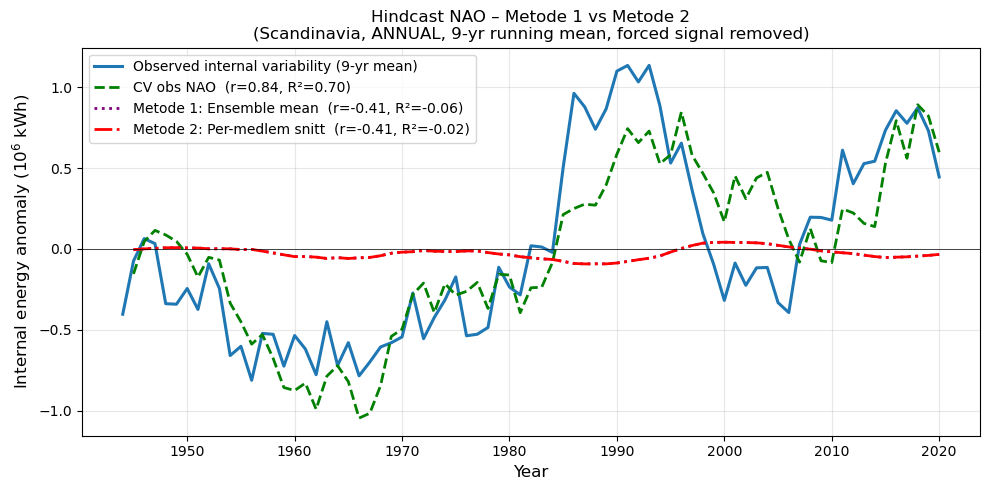

In [10]:
# PLOTT: observert, CV (obs-NAO), Metode 1 og Metode 2
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nao_al["time"].values, energy_al.values / ENERGY_SCALE,
        label="Observed internal variability (9-yr mean)",
        linewidth=2.2, color="tab:blue")
ax.plot(cv["res_cv"]["test_center"], cv["res_cv"]["energy_pred"] / ENERGY_SCALE,
        label=f"CV obs NAO  (r={cv['corr']:.2f}, R²={cv['r2_cv']:.2f})",
        linewidth=2.0, color="green", linestyle="--")
ax.plot(df_D["test_center"], df_D["energy_pred"] / ENERGY_SCALE,
        label=f"Metode 1: Ensemble mean  (r={r_D:.2f}, R²={r2_D:.2f})",
        linewidth=2.0, color="purple", linestyle=":")
ax.plot(mean_pred_B["test_center"], mean_pred_B["energy_pred"] / ENERGY_SCALE,
        label=f"Metode 2: Per-medlem snitt  (r={mean_r_B:.2f}, R²={mean_r2_B:.2f})",
        linewidth=2.0, color="red", linestyle="-.")
ax.axhline(0, color="k", linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(ENERGY_LABEL, fontsize=12)
ax.set_title(
    f"Hindcast NAO – Metode 1 vs Metode 2\n"
    f"({REGION_NAME}, {PERIOD}, {WINDOW}-yr running mean, forced signal removed)",
    fontsize=12)
ax.legend(fontsize=10, frameon=True, facecolor="white", edgecolor="0.8")
plt.tight_layout()
plt.show()

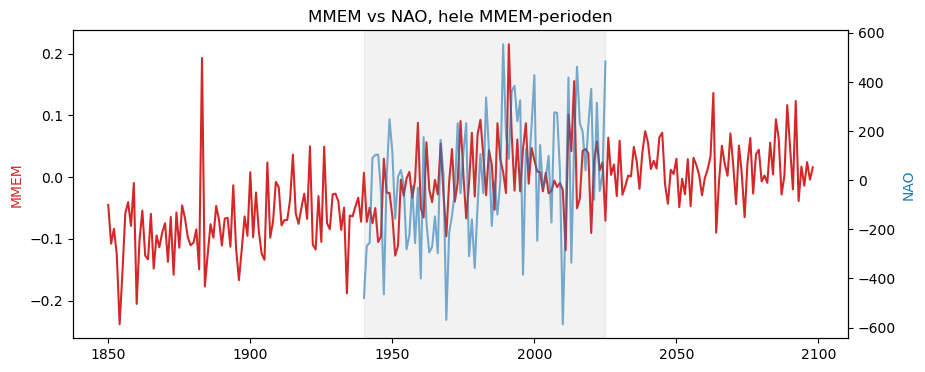

MMEM std i 1940-2025: 0.059785298742141446
MMEM trend i 1940-2025 (siste-første): -0.07776261642726139


In [11]:
# Sammenligning av MMEM og NAO over hele MMEM-perioden (1850-2098).
# Den grå skyggen markerer observasjonsperioden (1940-2025).
# Brukes for å vurdere om MMEM ser ut som et typisk forced signal
# (glatt, systematisk trend) eller om det er mye år-til-år støy.

import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10,4))
ax1.plot(mmem_c.year, mmem_c, color="tab:red", label="MMEM (1850-2098)")
ax1.set_ylabel("MMEM", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(nao_c.time, nao_c, color="tab:blue", alpha=0.6, label="NAO_eof_raw")
ax2.set_ylabel("NAO", color="tab:blue")
plt.axvspan(1940, 2025, alpha=0.1, color="gray")
plt.title("MMEM vs NAO, hele MMEM-perioden")
plt.show()

# Og se konkret hvordan MMEM ser ut KUN i observasjonsperioden
mmem_obs_period = mmem_c.sel(year=slice(1940,2025))
print("MMEM std i 1940-2025:", float(mmem_obs_period.std()))
print("MMEM trend i 1940-2025 (siste-første):", float(mmem_obs_period.isel(year=-1) - mmem_obs_period.isel(year=0)))

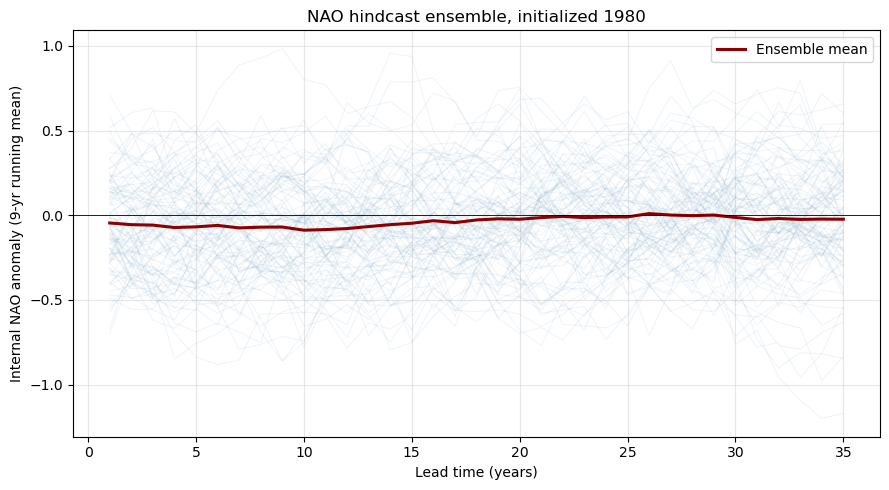

In [12]:
# Visualisering av hindcast-ensemblet for ett representativt startår.
# Viser alle 100 medlemmer (blå) og ensemble-gjennomsnittet (rød).
# Ensemble-gjennomsnittet ligger konsekvent nær null, mens spredningen mellom medlemmer er stor 

ds_h = xr.open_dataset("NAO_HadSLP_analog_hindcast_anomalies.nc")

# Velg et representativt startår 
example_init_year = 1980
data = ds_h["scores"].sel(init_year=example_init_year)

lead_time = data["lead_time"].values
ensemble_mean = data.mean(dim="member")

fig, ax = plt.subplots(figsize=(9, 5))

# Alle 100 medlemmer i bakgrunnen
for m in data["member"].values:
    ax.plot(lead_time, data.sel(member=m).values,
            color="steelblue", alpha=0.08, linewidth=0.8)

# Ensemble-gjennomsnitt foran
ax.plot(lead_time, ensemble_mean.values,
        color="darkred", linewidth=2.2, label="Ensemble mean")

ax.axhline(0, color="black", linewidth=0.6)
ax.set_xlabel("Lead time (years)")
ax.set_ylabel("Internal NAO anomaly (9-yr running mean)")
ax.set_title(f"NAO hindcast ensemble, initialized {example_init_year}")
ax.legend(frameon=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("hindcast_ensemble_example.png", dpi=300)
plt.show()